# 第3章 时间数据可视化 · 课件案例复刻

对应课件：`第3章-时间数据.pdf`；数据文件在 `data/` 下。

| 案例 | 图表 | 库 |
|---|---|---|
| 1 | 美国邮费阶梯图 | pyecharts |
| 2 | 美国邮费折线图（固定 y 轴范围） | pyecharts |
| 3 | 世界人口折线图 | matplotlib |
| 4 | 美国失业率散点图 + 三次多项式拟合 | matplotlib |
| 5 | FlowingData 订阅量散点图 | matplotlib |
| 6 | 热狗大胃王柱形图 | pyecharts |
| 7 | 热狗大胃王堆叠柱形图 | pyecharts |
| 实验 | 极坐标堆叠柱状图（两种时间轴） | pyecharts |

> 运行顺序：从上到下执行。pyecharts 图表需要联网加载 ECharts 资源。


In [1]:
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display
from pyecharts import options as opts
from pyecharts.charts import Bar, Line, Page, Polar
from pyecharts.globals import CurrentConfig, ThemeType

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# 课件默认的 assets.pyecharts.org 在当前网络不可达，改用可访问的 jsDelivr
CurrentConfig.ONLINE_HOST = "https://fastly.jsdelivr.net/gh/pyecharts/pyecharts-assets@master/assets/v5/"

BASE = Path.cwd()
DATA = BASE / "data"
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)
assert DATA.exists(), f"找不到数据目录: {DATA}"
print("数据目录:", DATA)


数据目录: /Users/aoetc/Developer/python-learn/exercises/dataviz/ch03_time/data


## 案例 1　美国邮费阶梯图（pyecharts）

In [2]:
# 2. 梯形图（阶梯图）：美国邮费变化
postage_years = [
    "1995", "1996", "1997", "1998", "1999", "2000", "2001",
    "2002", "2003", "2004", "2005", "2006", "2007", "2008", "2009",
]
postage = [
    0.32, 0.32, 0.32, 0.32, 0.33, 0.33, 0.34,
    0.37, 0.37, 0.37, 0.37, 0.39, 0.41, 0.42, 0.44,
]

(
    Line()
    .add_xaxis(xaxis_data=postage_years)
    .add_yaxis(
        series_name="美国邮费",
        y_axis=postage,
        symbol="emptyCircle",
        is_step=True,
    )
    .render_notebook()
)


## 案例 2　美国邮费折线图 + 固定 y 轴（pyecharts）

In [3]:
# 3. 折线图：同样的邮费数据，is_step=False
(
    Line()
    .add_xaxis(xaxis_data=postage_years)
    .add_yaxis(
        series_name="美国邮费",
        y_axis=postage,
        symbol="emptyCircle",
        is_step=False,
    )
    .set_global_opts(
        yaxis_opts=opts.AxisOpts(min_=0.3, max_=0.45)
    )
    .render_notebook()
)


## 案例 3　世界人口折线图（matplotlib）

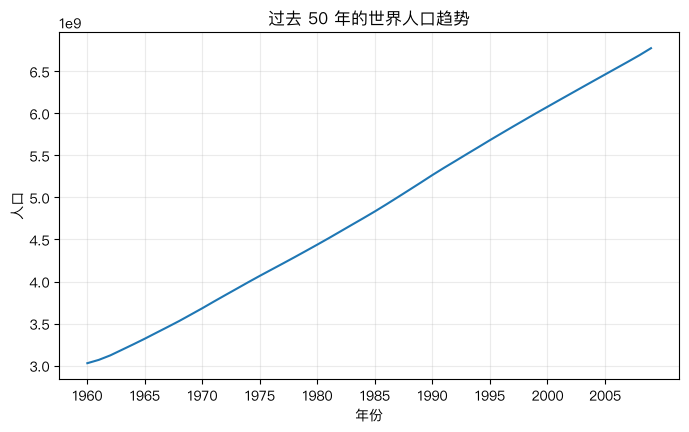

In [4]:
# 3. 折线图：过去 50 年世界人口
world_years = []
world_pop = []
with open(DATA / "world-population.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    next(reader)  # 跳过表头
    for row in reader:
        world_years.append(int(row[0]))
        world_pop.append(int(row[1]))

plt.figure(figsize=(8, 4.5))
plt.plot(world_years, world_pop)
plt.xticks(np.arange(1960, 2010, 5))
plt.yticks(np.arange(3e9, 7e9, 5e8))
plt.title("过去 50 年的世界人口趋势")
plt.xlabel("年份")
plt.ylabel("人口")
plt.grid(alpha=0.25)
plt.show()


## 案例 4　美国失业率散点图 + 三次多项式拟合（matplotlib）

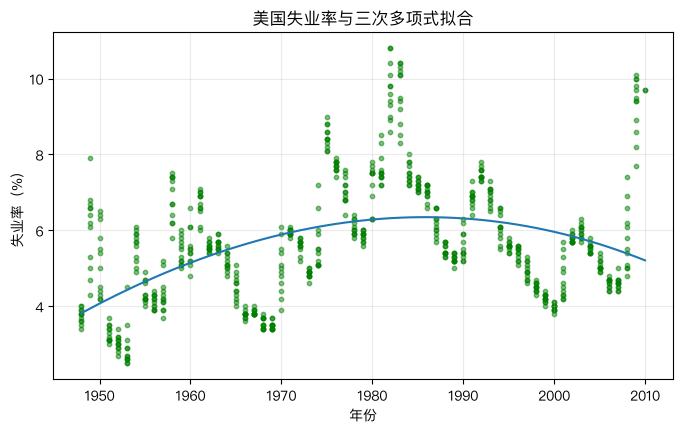

In [5]:
# 4. 拟合曲线：美国失业率（1948–2010），三次多项式
unemp_years = []
unemp_rates = []
with open(DATA / "unemployment-rate-1948-2010.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        unemp_years.append(int(row[1]))
        unemp_rates.append(float(row[3]))

plt.figure(figsize=(8, 4.5))
plt.scatter(unemp_years, unemp_rates, s=10, c="g", marker="o", alpha=0.5)

poly = np.polyfit(unemp_years, unemp_rates, deg=3)
plt.plot(unemp_years, np.polyval(poly, unemp_years), color="tab:blue")

plt.title("美国失业率与三次多项式拟合")
plt.xlabel("年份")
plt.ylabel("失业率（%）")
plt.grid(alpha=0.25)
plt.show()


## 案例 5　FlowingData 订阅量散点图（matplotlib）

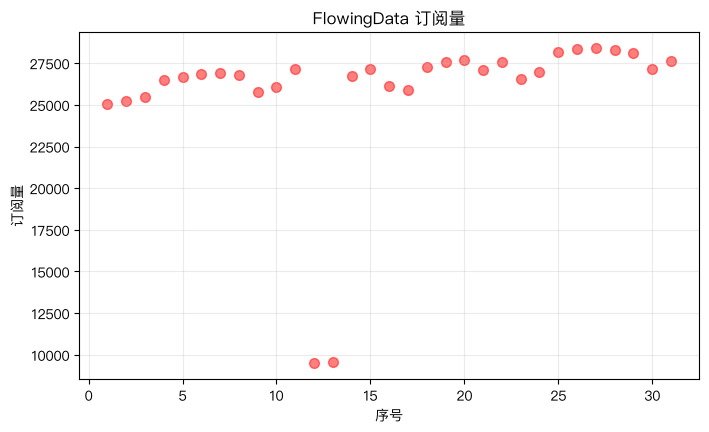

In [6]:
# 2. 散点图：FlowingData 订阅量
subs = []
with open(DATA / "subscribers.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        subs.append(int(row[1]))

subs_x = list(range(1, len(subs) + 1))

plt.figure(figsize=(8, 4.5))
plt.scatter(subs_x, subs, s=50, c="r", marker="o", alpha=0.5)
plt.title("FlowingData 订阅量")
plt.xlabel("序号")
plt.ylabel("订阅量")
plt.grid(alpha=0.25)
plt.show()


## 案例 6　热狗大胃王柱形图（pyecharts）

In [7]:
# 3. 柱形图：热狗大胃王比赛成绩
hotdog_years = []
hotdog_dogs = []
with open(DATA / "hot-dog-contest-winners.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        hotdog_years.append(row[0])
        hotdog_dogs.append(float(row[2]))

(
    Bar()
    .add_xaxis(hotdog_years)
    .add_yaxis("热狗比赛", hotdog_dogs)
    .set_global_opts(title_opts=opts.TitleOpts(title="大胃王比赛成绩"))
    .render_notebook()
)


## 案例 7　热狗大胃王堆叠柱形图（pyecharts）

In [8]:
# 4. 堆叠柱形图：热狗大胃王前三名
places = []
with open(DATA / "hot-dog-places.csv", newline="", encoding="utf-8-sig") as f:
    places = list(csv.reader(f))

places_years = places[0]
first = [float(v) for v in places[1]]
second = [float(v) for v in places[2]]
third = [float(v) for v in places[3]]

(
    Bar()
    .add_xaxis(places_years)
    .add_yaxis("第一名", first, stack="all")
    .add_yaxis("第二名", second, stack="all")
    .add_yaxis("第三名", third, stack="all")
    .set_global_opts(title_opts=opts.TitleOpts(title="热狗大胃王的堆叠柱形图"))
    .render_notebook()
)


## 实验　极坐标堆叠柱状图（南丁格尔玫瑰图）

In [9]:
# 实验：极坐标-堆叠柱状图实例 1
# 用角度轴表示年份（时间绕圆周排列）
a = (
    Polar(init_opts=opts.InitOpts(theme=ThemeType.CHALK))
    .set_global_opts(title_opts=opts.TitleOpts(title="极坐标-堆叠柱状图实例1"))
    .add_schema(angleaxis_opts=opts.AngleAxisOpts(data=places_years))
    .add("A", first, type_="bar", stack="1")
    .add("B", second, type_="bar", stack="1")
    .add("C", third, type_="bar", stack="1")
)
a.render_notebook()


In [10]:
# 实验：极坐标-堆叠柱状图实例 2
# 用半径轴表示年份
b = (
    Polar(init_opts=opts.InitOpts(theme=ThemeType.CHALK))
    .set_global_opts(title_opts=opts.TitleOpts(title="极坐标-堆叠柱状图实例2"))
    .add_schema(radiusaxis_opts=opts.RadiusAxisOpts(data=places_years))
    .add("A", first, type_="bar", stack="1")
    .add("B", second, type_="bar", stack="1")
    .add("C", third, type_="bar", stack="1")
)
b.render_notebook()


In [11]:
# 把两张极坐标图放进同一个 Page，并保存为 HTML
page = Page().add(a).add(b)
page.render(str(OUT / "polar_stacked.html"))
display(page.render_notebook())
print("已保存:", OUT / "polar_stacked.html")


已保存: /Users/aoetc/Developer/python-learn/exercises/dataviz/ch03_time/output/polar_stacked.html
